In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
import umap

from utils import load_config, output_dir, latest_experiment_dir

# ---- UMAP 兼容性 patch（防重复运行版）----
import sklearn.utils.validation as _validation

# 只在第一次运行时保存真正的原始函数
if not hasattr(_validation, "_codex_orig_check_array"):
    _validation._codex_orig_check_array = _validation.check_array

_orig = _validation._codex_orig_check_array

def _patched(array, accept_sparse=False, *, accept_large_sparse=True,
             dtype="numeric", order=None, copy=False,
             force_all_finite="deprecated", ensure_2d=True,
             allow_nd=False, ensure_min_samples=1, ensure_min_features=1,
             estimator=None, input_name="", **kwargs):
    # 把旧的 force_all_finite 转成新的 ensure_all_finite
    if "ensure_all_finite" not in kwargs:
        if force_all_finite == "deprecated":
            kwargs["ensure_all_finite"] = True
        else:
            kwargs["ensure_all_finite"] = force_all_finite
    # 删除旧参数名
    kwargs.pop("force_all_finite", None)
    return _orig(array, accept_sparse=accept_sparse,
                 accept_large_sparse=accept_large_sparse,
                 dtype=dtype, order=order, copy=copy,
                 ensure_2d=ensure_2d, allow_nd=allow_nd,
                 ensure_min_samples=ensure_min_samples,
                 ensure_min_features=ensure_min_features,
                 estimator=estimator, input_name=input_name, **kwargs)

_validation.check_array = _patched
# ---------------------------

# ---- 配置 ----
EXP_NAME = None  # 填 "exp_032" 或保持 None 使用最新 exp
cfg = load_config()
out = output_dir(cfg)

if EXP_NAME:
    exp_dir = out / EXP_NAME if str(EXP_NAME).startswith("exp_") else out / f"exp_{int(EXP_NAME):03d}"
else:
    exp_dir = latest_experiment_dir(cfg)

print(f"实验目录: {exp_dir}")

feat_files = sorted(exp_dir.glob("segment_features_*.npz"))
feat_path = feat_files[-1]
print(f"特征文件: {feat_path.name}")

data = np.load(feat_path, allow_pickle=True)
X_raw = data["features"].astype(float)
meta = data["meta"].tolist()

print(f"片段数: {len(X_raw)}, 特征维度: {X_raw.shape[1]}")

# ---- 预处理 ----
# 1. 异常值过滤
z = np.abs((X_raw - X_raw.mean(axis=0)) / (X_raw.std(axis=0) + 1e-10))
mask = (z <= 35.0).all(axis=1)
X = X_raw[mask]
meta = [m for i, m in enumerate(meta) if mask[i]]
print(f"过滤后片段数: {len(X)}")

# 2. z-score
scaler = StandardScaler()
X_z = scaler.fit_transform(X)

# 3. PCA
pca_dim = min(30, X_z.shape[0] - 1, X_z.shape[1])
pca = PCA(n_components=pca_dim, random_state=0)
X_pca = pca.fit_transform(X_z)
print(f"PCA: {pca_dim} 维, 解释方差比: {pca.explained_variance_ratio_.sum():.3f}")

states = np.array([m["state"] for m in meta])
recordings = [m["recording"] for m in meta]

实验目录: F:\IMU_computational_ethology\Data\VAME-Style-Data\Batch2\exp_003
特征文件: segment_features_exp_003.npz
片段数: 36813, 特征维度: 154
过滤后片段数: 36745
PCA: 30 维, 解释方差比: 0.887


In [ ]:
K_MIN = 5
K_MAX = 30
RANDOM_STATE = 0

bics, aics = [], []
valid_k = []

for k in range(K_MIN, K_MAX + 1):
    if k >= len(X_pca):
        break
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=RANDOM_STATE,
        max_iter=300,
        n_init=5,
    )
    gmm.fit(X_pca)
    bics.append(gmm.bic(X_pca))
    aics.append(gmm.aic(X_pca))
    valid_k.append(k)
    print(f"K={k:2d}: BIC={gmm.bic(X_pca):.1f}  AIC={gmm.aic(X_pca):.1f}")

# 画图
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(valid_k, bics, "o-", label="BIC")
ax.plot(valid_k, aics, "s-", label="AIC", alpha=0.7)
best_k = valid_k[int(np.argmin(bics))]
ax.axvline(best_k, color="r", linestyle="--", label=f"BIC best K={best_k}")
ax.set_xlabel("K")
ax.set_ylabel("score")
ax.set_title("GMM model selection")
ax.legend()
plt.show()

print(f"\n建议 K = {best_k}")

In [3]:
# 在这里手动修改 K 和随机种子
K = 29
RANDOM_STATE = 0

print(f"使用 K = {K}")

gmm = GaussianMixture(
    n_components=K,
    covariance_type="full",
    random_state=RANDOM_STATE,
    max_iter=300,
    n_init=5,
)
gmm.fit(X_pca)
labels = gmm.predict(X_pca)

print("Cluster sizes:")
for k in range(K):
    print(f"  cluster {k:2d}: {(labels == k).sum()}")

使用 K = 29


D:\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系统找不到指定的文件。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "D:\Anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "D:\Anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


Cluster sizes:
  cluster  0: 1188
  cluster  1: 2415
  cluster  2: 22
  cluster  3: 1484
  cluster  4: 2295
  cluster  5: 1325
  cluster  6: 4
  cluster  7: 1480
  cluster  8: 1589
  cluster  9: 2085
  cluster 10: 1656
  cluster 11: 478
  cluster 12: 1292
  cluster 13: 7
  cluster 14: 1253
  cluster 15: 574
  cluster 16: 1408
  cluster 17: 1256
  cluster 18: 1644
  cluster 19: 1501
  cluster 20: 9
  cluster 21: 1103
  cluster 22: 679
  cluster 23: 1928
  cluster 24: 1338
  cluster 25: 2396
  cluster 26: 1578
  cluster 27: 772
  cluster 28: 1986


In [4]:
reducer = umap.UMAP(
    n_neighbors=min(15, len(X_pca) - 1),
    min_dist=0.1,
    random_state=RANDOM_STATE,
)
emb = reducer.fit_transform(X_pca)
print(f"UMAP embedding shape: {emb.shape}")

f:\Kimi\IMU\v3_recovery\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP embedding shape: (36745, 2)


f:\Kimi\IMU\v3_recovery\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
f:\Kimi\IMU\v3_recovery\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
f:\Kimi\IMU\v3_recovery\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
f:\Kimi\IMU\v3_recovery\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
f:\Kimi\IMU\v3_recovery\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
f:\Kimi\IMU\v3_recovery\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state.

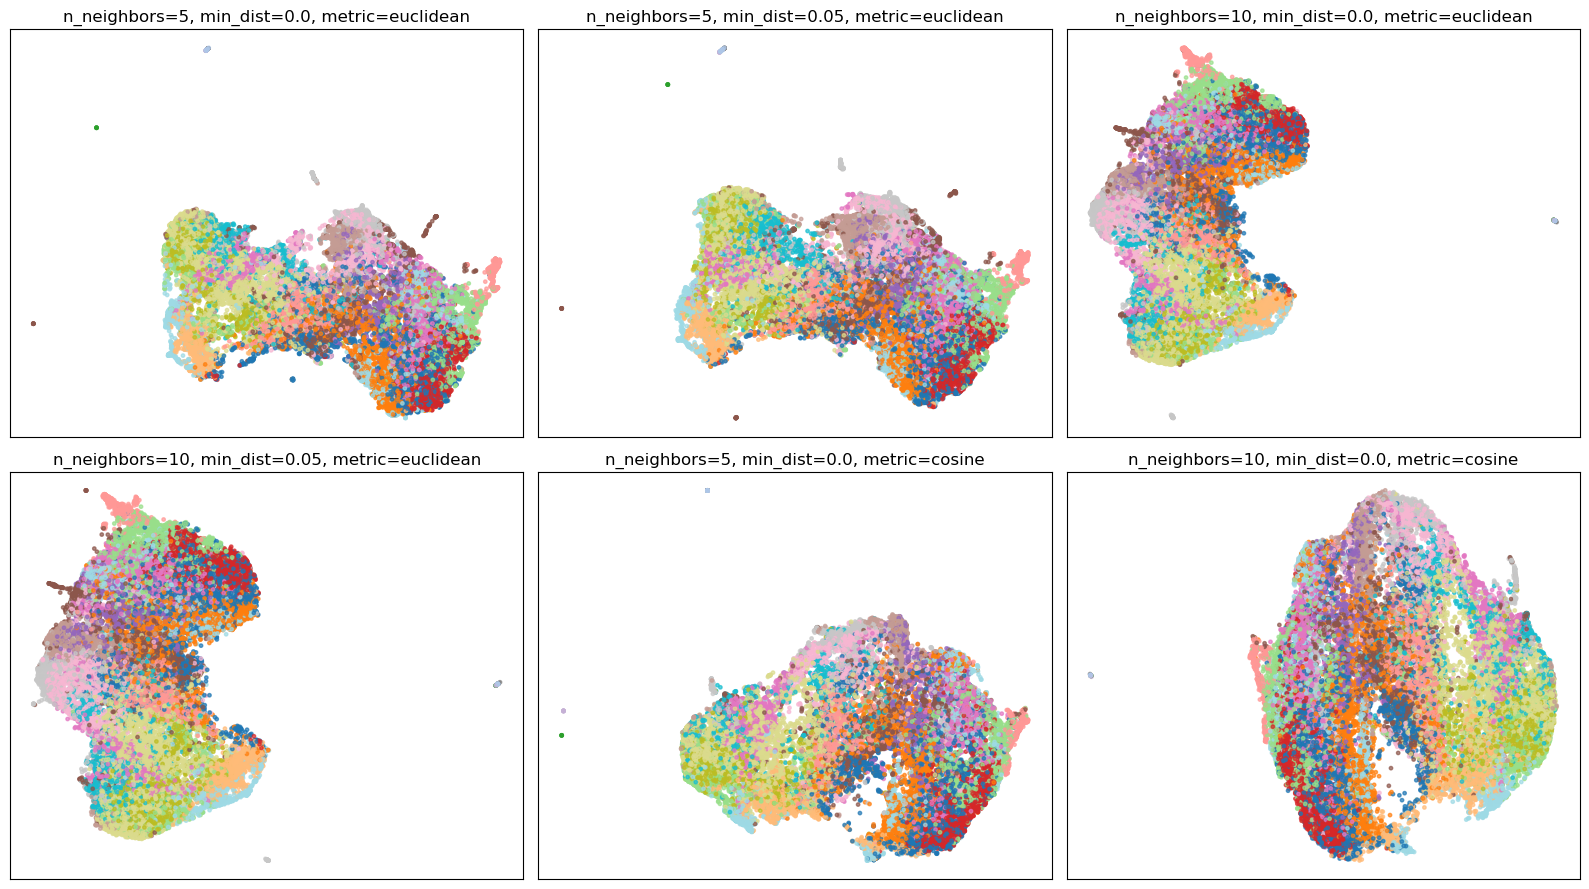

使用最佳参数: {'n_neighbors': 5, 'min_dist': 0.0, 'metric': 'euclidean'}


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import umap

# 多组 UMAP 参数
param_grid = [
    {"n_neighbors": 5,  "min_dist": 0.0,  "metric": "euclidean"},
    {"n_neighbors": 5,  "min_dist": 0.05, "metric": "euclidean"},
    {"n_neighbors": 10, "min_dist": 0.0,  "metric": "euclidean"},
    {"n_neighbors": 10, "min_dist": 0.05, "metric": "euclidean"},
    {"n_neighbors": 5,  "min_dist": 0.0,  "metric": "cosine"},
    {"n_neighbors": 10, "min_dist": 0.0,  "metric": "cosine"},
]

n_params = len(param_grid)
n_cols = 3
n_rows = int(np.ceil(n_params / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.5 * n_rows))
axes = axes.flatten() if n_params > 1 else [axes]

embeddings = {}

for ax, params in zip(axes, param_grid):
    reducer = umap.UMAP(
        n_neighbors=params["n_neighbors"],
        min_dist=params["min_dist"],
        metric=params["metric"],
        random_state=RANDOM_STATE,
        n_components=2,
    )
    emb = reducer.fit_transform(X_pca)
    embeddings[str(params)] = emb

    sc = ax.scatter(emb[:, 0], emb[:, 1], c=labels, cmap="tab20", s=6, alpha=0.7)
    ax.set_title(f"n_neighbors={params['n_neighbors']}, "
                 f"min_dist={params['min_dist']}, "
                 f"metric={params['metric']}")
    ax.set_xticks([])
    ax.set_yticks([])

# 隐藏多余的子图
for ax in axes[n_params:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 选择最好的一组参数保存
# 你可以根据肉眼观察手动修改这里
BEST_PARAMS = {"n_neighbors": 5, "min_dist": 0.0, "metric": "euclidean"}
emb_best = embeddings[str(BEST_PARAMS)]
print(f"使用最佳参数: {BEST_PARAMS}")

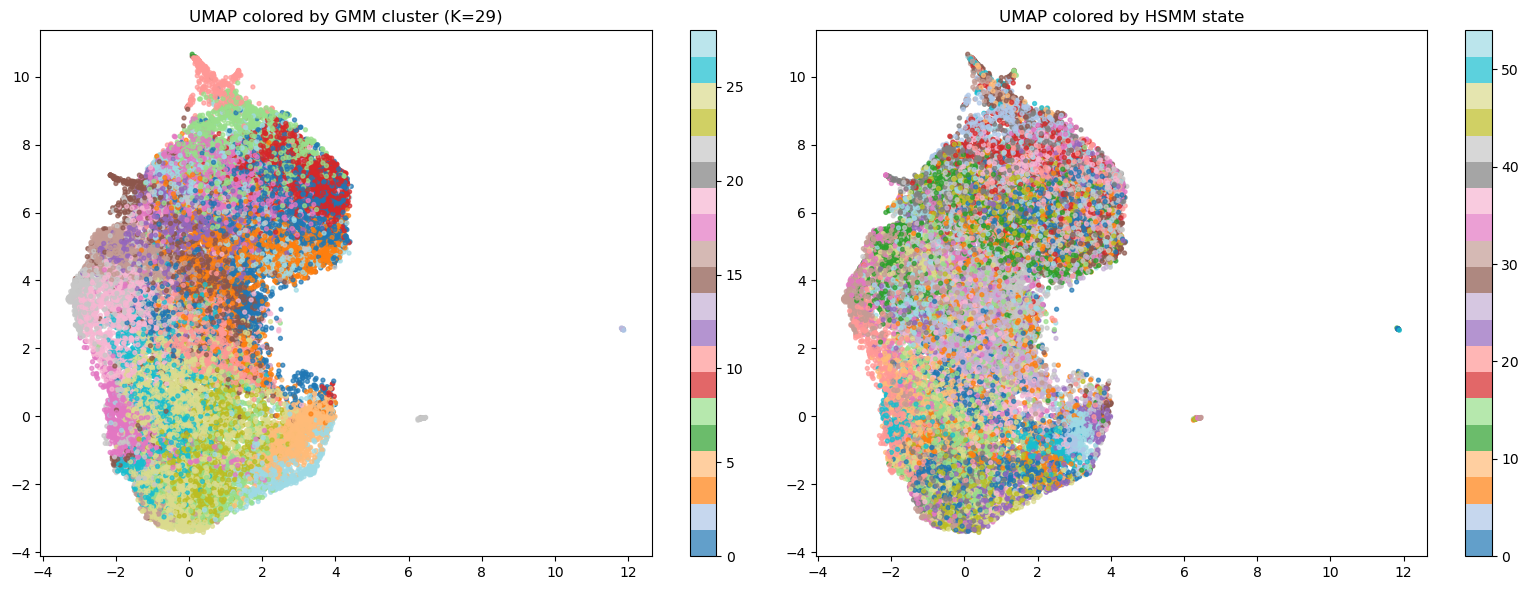

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 按 GMM cluster 上色
ax = axes[0]
sc = ax.scatter(emb[:, 0], emb[:, 1], c=labels, cmap="tab20", s=8, alpha=0.7)
ax.set_title(f"UMAP colored by GMM cluster (K={K})")
plt.colorbar(sc, ax=ax)

# 按 HSMM state 上色
ax = axes[1]
sc = ax.scatter(emb[:, 0], emb[:, 1], c=states, cmap="tab20", s=8, alpha=0.7)
ax.set_title("UMAP colored by HSMM state")
plt.colorbar(sc, ax=ax)

plt.tight_layout()
plt.show()